# Diabetes Hybrid Lab
## A student project report on deep learning, knowledge graphs, and multi-agent systems

**Project question.** How can a survey classifier and a source-grounded information assistant be integrated in one educational prototype while keeping their conclusions separate?

**Answer in brief.** The demo reuses the original Assignment 4 checkpoint on BRFSS. We separately evaluated a grouped model on 253,680 BRFSS records, measured two additional diabetes-related tasks, and integrated a Neo4j knowledge base assembled from 22 independently managed source files.

### 1. Introduction and scope

Type 2 diabetes is a chronic metabolic condition that can develop with mild symptoms. Reliable information about screening and complications is valuable when people are deciding what to discuss with a healthcare professional. In this project the intended users are students and instructors. A demo user can select a synthetic survey profile, ask an educational question, or use both paths together. The system reports survey-class scores and cited information as separate outputs. A cross-sectional survey label supports retrospective classification. A future-incidence prediction would require follow-up observations and a different study design.

The assistant explains tests, symptoms, and general next steps. It routes requests about personal results and medication decisions to qualified care. Clinical diagnosis, drug advice, and actual triage require independent clinical validation. Our rule tests show how the implementation behaves on selected examples. [WHO diabetes fact sheet](https://www.who.int/news-room/fact-sheets/detail/diabetes)


In [1]:
from pathlib import Path
import json
import sys

current = Path.cwd()
candidates = [current, *current.parents, current / "diabetes_hybrid"]
root = next((directory for directory in candidates if (directory / "app.py").is_file()
             and (directory / "artifacts/experiment.json").is_file()), current)
assert (root / "artifacts/experiment.json").is_file(), "Start in the project folder or its parent."
sys.path.insert(0, str(root.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
ink, teal, amber = "#17383c", "#087569", "#aa5526"
figures = root / "artifacts/figures"
figures.mkdir(exist_ok=True)

def read(path):
    return json.loads(path.read_text(encoding="utf-8"))

def artifact(name):
    return read(root / "artifacts" / name)

def emit(fig, file_name):
    fig.savefig(figures / f"{file_name}.png", dpi=155, bbox_inches="tight")
    plt.show()
    plt.close(fig)

brfss = artifact("experiment.json")
checks = artifact("demo_verification.json")
print("Training environment:", brfss["versions"])
print("Model and seed:", brfss["training_config"]["model_version"], brfss["seed"])

Training environment: {'python': '3.13.1', 'torch': '2.14.0+cpu', 'pandas': '2.3.3', 'sklearn': '1.9.0'}
Model and seed: brfss-mlp-v2 42


## 2. Multi-agent architecture and execution flow

### Question. Why use multiple agents, and what does each agent do?

**Answer.** An agent is a software component that receives information, makes a decision or performs an assigned operation, and returns a result. The prototype is a centralized multi-agent system. The Coordinator assigns work to components with different responsibilities. The Data Agent checks inputs, the Prediction Agent applies the MLP, the Rule Agent controls scope and escalation, the Knowledge Agent queries Neo4j, the Explanation Agent checks the sources and formats the answer, and Monitoring records the trace. The split makes it possible to test and fail individual components independently. A single component would be simpler to run, but would couple health-information rules, database access, and inference. The trade-off is orchestration overhead and more interfaces to maintain.

| Agent | Input | Output | Example failure |
|---|---|---|---|
| Coordinator | Mode, synthetic profile, and/or question | Separate prediction, answer, and trace | Unknown mode returns a validation error |
| Data Agent | 21 survey fields | Ordered numeric vector | Missing or out-of-range field stops the combined request |
| Prediction Agent | Validated vector | Three softmax scores and model version | Missing checkpoint returns an unavailable state |
| Rule Agent | Question or model scores | Scope decision, guidance, or close-score flag | Red-flag wording triggers emergency guidance |
| Knowledge Agent | Scoped question and optional topic ID | Evidence, source URLs, and graph paths | Offline Neo4j or insufficient evidence |
| Explanation Agent | Retrieved evidence | Source-checked extractive answer | No approved source means abstention |
| Monitoring | Agent status and timing | Trace with a shared request ID | Payload is restricted to summaries |

The figure distinguishes a synthetic prediction path from the education path. Monitoring records a message with request ID, agent, status, evidence identifiers, version, and duration. The data agent never sends scores to retrieval.

**Mapping to the specification.** The six layers are the browser, Flask and validation, Coordinator, specialized agents, model and Neo4j services, and monitoring and evaluation. The centralized prototype can be represented as $M=(A,S,O,C,F)$. Here $A$ is the seven implemented agents, $S$ is the per-request state, $O$ contains validated observations and intermediate results, $C$ is the structured message contract, and $F$ is the Coordinator's aggregation function. For each agent, $A_i:X_i\rightarrow Y_i$ maps a defined input to a result. The optional RL simulation is outside the first implementation.

The Data Agent passes an ordered feature vector in a private message. The Prediction Agent passes scores and its model version to the Rule Agent. The Explanation Agent receives prediction, rules, and evidence separately and returns a single report with limitations and review status. The public trace shows a summary and metadata rather than feature values or raw questions.


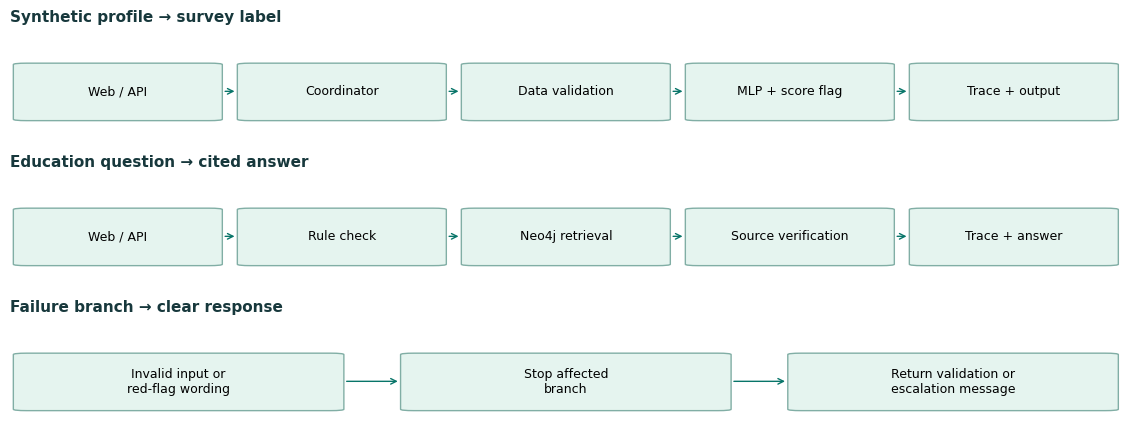

In [2]:
from matplotlib.patches import FancyBboxPatch

def flow_diagram(panels):
    fig, axes = plt.subplots(len(panels), 1, figsize=(11.2, len(panels) * 1.45), layout="constrained")
    for ax, (title, boxes) in zip(np.atleast_1d(axes), panels):
        ax.set_axis_off()
        ax.set_title(title, loc="left", fontsize=11, color=ink, fontweight="bold")
        width = .82 / len(boxes)
        gap = .15 / max(1, len(boxes) - 1)
        for i, label in enumerate(boxes):
            x = .015 + i * (width + gap)
            ax.add_patch(FancyBboxPatch((x, .23), width, .47, boxstyle="round,pad=0.012",
                                       facecolor="#e5f4ef", edgecolor="#81aea5", transform=ax.transAxes))
            ax.text(x + width / 2, .47, label, ha="center", va="center", transform=ax.transAxes, fontsize=9)
            if i < len(boxes) - 1:
                ax.annotate("", xy=(x + width + gap - .012, .47), xytext=(x + width + .012, .47),
                            xycoords=ax.transAxes, arrowprops={"arrowstyle": "->", "color": teal})
    return fig

emit(flow_diagram([
    ("Synthetic profile → survey label", ["Web / API", "Coordinator", "Data validation", "MLP + score flag", "Trace + output"]),
    ("Education question → cited answer", ["Web / API", "Rule check", "Neo4j retrieval", "Source verification", "Trace + answer"]),
    ("Failure branch → clear response", ["Invalid input or\nred-flag wording", "Stop affected\nbranch", "Return validation or\nescalation message"]),
]), "01_agent_flow")

### Question. What happens during one combined request?

**Answer.** The browser sends the mode, a synthetic profile preset, and an educational question. The backend validates the profile and invokes the predictor. It applies the score rule and, when a question is supplied, checks the question before retrieving evidence. The response includes a public trace. When Neo4j is offline, the model branch remains available. The latency bar chart below is one measured run. The Monitoring duration covers the entire request, so it should not be added to the other durations.

To assess architectural choices, we compare direct retrieval, the deployed multi-agent route, and an offline ablation that temporarily removes the question gate. Each method is run on the same six predefined cases over three repeats. Expected-status agreement measures the routing contract, not medical correctness. The no-rule variant exists only inside the evaluation harness.

The sequence diagram below orders the major messages for one successful combined request. It is a logical diagram; the bar chart above is the empirical timing trace.

A question is optional in combined mode. When it is absent, the data and model path completes and the report marks the question branch as not requested. If evidence sources disagree on the same curated scope key, the report shows the conflicting sources and asks for professional review without selecting a claim. Close model scores trigger a separate review reason. This narrow evidence check uses annotated assertions and does not detect contradictions in unrestricted prose.


,agent,status,version,evidence,elapsed_ms
0,Coordinator,started,hybrid-3,[],0.02
1,Data Agent,ok,hybrid-3,[],0.03
2,DL Prediction Agent,ok,assignment4-original,[],0.58
3,Rule Agent,ok,hybrid-3,[],0.01
4,Rule Agent,ok,hybrid-3,[],0.63
5,KG/RAG Agent,ok,hybrid-3,"[p03, p02]",33.57
6,Explanation Agent,ok,hybrid-3,"[p03, p02]",0.04
7,Monitoring Agent,ok,hybrid-3,[],34.91


Report fields: error, knowledge, limitations, prediction, request_id, review, rules, status
Review: none | Prediction: assignment4-original
Public message fields: agent, elapsed_ms, evidence, payload, request_id, status, version


,method,requests,expected_status_matches,answers_with_sources,answers,median_ms
0,Direct retrieval,18,9,9,9,19.18
1,Multi-agent with rules,18,18,6,6,8.23
2,Multi-agent without question rules (offline),18,9,9,9,12.12


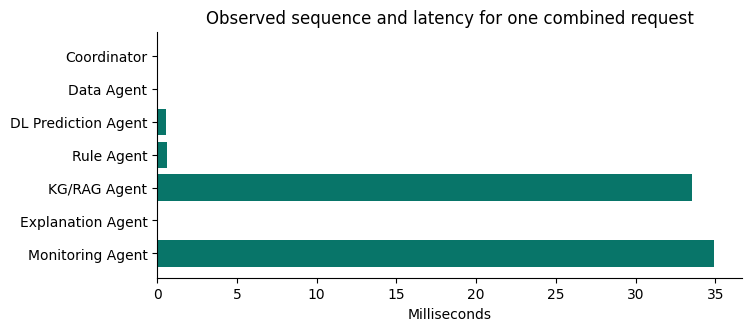

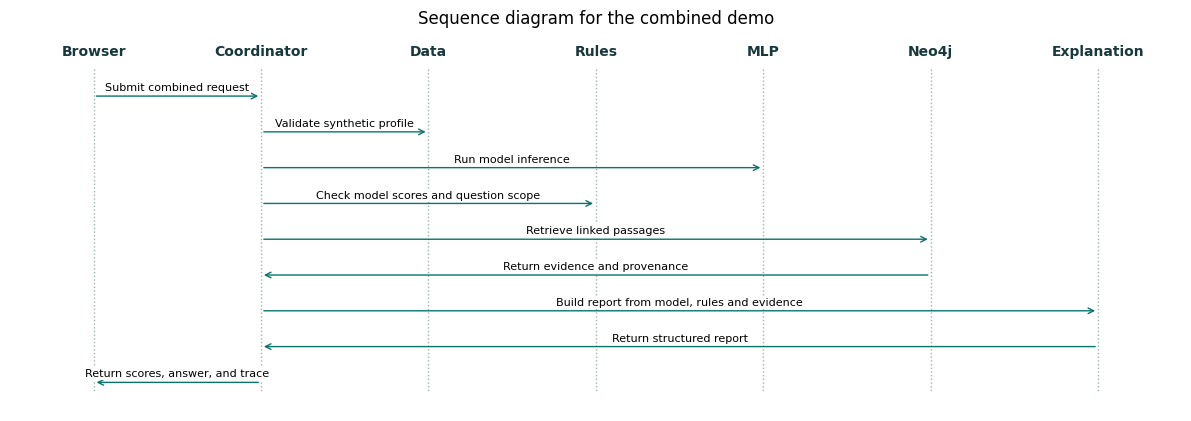

In [3]:
from app import app

client = app.test_client()
response = client.post("/api/run", json={"mode": "combined", "preset": "sample_b",
                                         "question": "How is type 1 diabetes diagnosed?"})
assert response.status_code == 200
combined = response.get_json()
trace = pd.DataFrame(combined["trace"])
display(trace[["agent", "status", "version", "evidence", "elapsed_ms"]])
report = combined["report"]
print("Report fields:", ", ".join(report))
print("Review:", report["review"]["status"], "| Prediction:", report["prediction"]["model_version"])
message = next(event for event in combined["trace"] if event["agent"] == "DL Prediction Agent")
assert isinstance(message["payload"], dict)
print("Public message fields:", ", ".join(message))
display(pd.DataFrame(checks["architecture_probe"]))

fig, ax = plt.subplots(figsize=(7.4, 3.2), layout="constrained")
ax.barh(trace["agent"], trace["elapsed_ms"], color=teal)
ax.invert_yaxis()
ax.set(xlabel="Milliseconds", title="Observed sequence and latency for one combined request")
emit(fig, "02_agent_latency")

lanes = ["Browser", "Coordinator", "Data", "Rules", "MLP", "Neo4j", "Explanation"]
messages = [
    (0, 1, "Submit combined request"),
    (1, 2, "Validate synthetic profile"),
    (1, 4, "Run model inference"),
    (1, 3, "Check model scores and question scope"),
    (1, 5, "Retrieve linked passages"),
    (5, 1, "Return evidence and provenance"),
    (1, 6, "Build report from model, rules and evidence"),
    (6, 1, "Return structured report"),
    (1, 0, "Return scores, answer, and trace"),
]
fig, ax = plt.subplots(figsize=(11.8, 4.1), layout="constrained")
ax.set_axis_off()
ax.set(xlim=(-.5,len(lanes)-.5), ylim=(len(messages)+.8,-.8),
       title="Sequence diagram for the combined demo")
for i, lane in enumerate(lanes):
    ax.text(i, -.15, lane, ha="center", fontweight="bold", color=ink)
    ax.plot([i,i],[.25,len(messages)+.25],color="#9cb5b0",linestyle=":", linewidth=1)
for i, (source, destination, title) in enumerate(messages, start=1):
    ax.annotate("", xy=(destination,i), xytext=(source,i),
                arrowprops={"arrowstyle":"->","color":teal})
    ax.text((source+destination)/2,i-.10,title,ha="center",va="bottom",fontsize=8,
            bbox={"facecolor":"white","edgecolor":"none","pad":1})
emit(fig, "09_sequence_diagram")

## 3. Deep learning

### Question. Which model did you use, and how does it learn?

**Answer.** The default deployed model is the original Assignment 4 fully connected multilayer perceptron (MLP) with widths **21 → 64 → 32 → 3** and ReLU hidden layers. Its existing weights and fitted scaler are reused without retraining. The separate grouped-evaluation MLP adds dropout and supplies the experiment analyzed below. An input vector contains a person's coded survey features. Hidden layers learn interactions among these features. The output layer has one logit per survey category. A CNN assumes meaningful local structure, which is useful for images. An RNN or LSTM assumes that order and history are meaningful, as in a time series. The BRFSS variables have neither input structure, so the MLP is a direct architectural fit.

For a layer with input $\mathbf{x}$, weights $W$, and biases $\mathbf{b}$, the forward calculation is $\mathbf{h}=\operatorname{ReLU}(W\mathbf{x}+\mathbf{b})$, where $\operatorname{ReLU}(t)=\max(0,t)$. The final layer outputs logits $z_c$. Softmax converts them into scores whose sum is one:

$$p_c=\frac{e^{z_c}}{\sum_{j=1}^{C}e^{z_j}}.$$

Here $C=3$. For logits $(2,1,0)$ the scores are approximately $(0.665,0.245,0.090)$. Argmax selects the largest score. Because training uses class weights, the raw scores should be evaluated for calibration before interpreting them as event probabilities.

The weighted cross-entropy over a batch is $-\sum_i w_{y_i}\log p_{i,y_i}/\sum_i w_{y_i}$. $y_i$ is the observed label, $w_{y_i}$ its training weight, and $p_{i,y_i}$ the score for the correct class. Binary cross-entropy is $-[y\log p+(1-y)\log(1-p)]$ for a single binary score. The two supplementary models instead use the equivalent two-logit categorical formulation with class weighting. Backpropagation applies the chain rule to compute gradients. AdamW adapts the update using gradient moments and applies decoupled weight decay. Learning rate controls the update scale, a batch is one update's data, and an epoch is a pass over training examples. Dropout discourages reliance on specific hidden units. Weak training and validation results can indicate underfitting, while an improving training curve paired with a deteriorating validation curve can indicate overfitting. Checkpoint selection and a patience rule use validation macro-F1.

**Hypothesis.** Nonlinear feature interactions could improve minority-class performance over a balanced linear baseline. We test that on the same held-out examples.

[PyTorch weighted cross-entropy documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)

In [4]:
import torch
from core.model import ARTIFACTS, FEATURES, Predictor, make_model
from experiments.train import DATA, main as train_brfss

original_meta = artifact("assignment4_original.json")
original = Predictor(ARTIFACTS / "assignment4_original.pt")
assert original_meta["saved_weights_match_original"]
print("Default inference checkpoint:", original.version)
display(original.model)
display(pd.DataFrame([{
    "Assignment 4 macro-F1": original_meta["archived_assignment_metrics"]["f1_macro"],
    "Assignment 4 accuracy": original_meta["archived_assignment_metrics"]["accuracy"],
    "Original-to-packaged parity checks": original_meta["inference_parity_profiles"],
}]).round(4))
print("Separate grouped-evaluation architecture:")
model = make_model()
display(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
display(pd.DataFrame([brfss["training_config"]]))
print("Softmax example:", torch.softmax(torch.tensor([2.0, 1.0, 0.0]), dim=0).numpy().round(3))

RETRAIN_BRFSS = False
if RETRAIN_BRFSS:
    train_brfss()
    brfss = artifact("experiment.json")

Default inference checkpoint: assignment4-original


Assignment4MLP(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)

,Assignment 4 macro-F1,Assignment 4 accuracy,Original-to-packaged parity checks
0,0.4252,0.64,2


Separate grouped-evaluation architecture:


Sequential(
  (0): Linear(in_features=21, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.15, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Linear(in_features=32, out_features=3, bias=True)
)

Trainable parameters: 3587


,model_version,layer_widths,batch_size,dropout,learning_rate,weight_decay,early_stopping_patience,maximum_epochs,decision_rule
0,brfss-mlp-v2,"[21, 64, 32, 3]",1024,0.15,0.001,0.0001,8,16,argmax


Softmax example: [0.665 0.245 0.09 ]


### Question. How was the MLP trained, selected, and evaluated?

**Answer.** For the separate grouped experiment, AdamW used learning rate 0.001, batch size 1,024 and inverse-frequency class weights. Early stopping is configured for eight epochs without validation improvement, with a maximum of 16 epochs. The saved model is the checkpoint at epoch 9. Each baseline sees the same training and test partition. The majority model predicts the most frequent class. Logistic regression uses class balancing and provides a linear comparator. For the three-class classifier, the decision rule was fixed as argmax before test evaluation.

Accuracy is the proportion correct. Precision is $TP/(TP+FP)$, recall is $TP/(TP+FN)$, and specificity is $TN/(TN+FP)$. $TP$, $FP$, $FN$ and $TN$ refer to the target class versus all others. F1 is the harmonic mean of precision and recall. Macro-F1 weights the classes equally, and balanced accuracy averages their recalls. ROC-AUC summarizes ranking across thresholds. Average precision summarizes the precision–recall curve and is useful under imbalance. Log loss penalizes low scores assigned to true classes. The multiclass Brier score is the mean sum of squared differences from one-hot labels and assesses probabilistic accuracy.

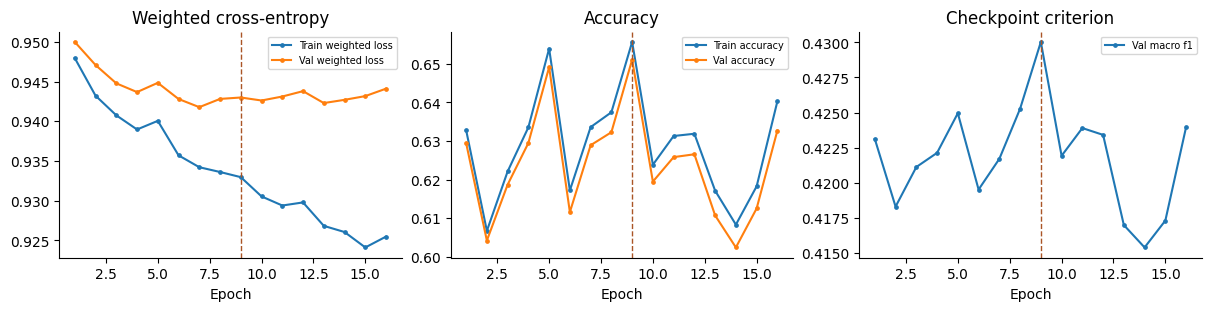

,accuracy,balanced_accuracy,macro_f1,roc_auc_ovr_macro,average_precision_macro,log_loss,brier_multiclass
Majority,0.8411,0.3333,0.3046,0.5000,0.3333,0.4930,0.2723
Logistic Regression,0.6407,0.5219,0.4249,0.7717,0.4617,0.8945,0.4955
MLP,0.6460,0.5140,0.4237,0.7708,0.4653,0.8175,0.4609


,precision,recall,specificity_ovr,f1-score,average_precision_ovr,support
0,0.9510,0.6541,0.8215,0.7751,0.9579,31910.0
1,0.0275,0.2395,0.8492,0.0493,0.0288,664.0
2,0.3407,0.6486,0.7933,0.4467,0.4094,5364.0


In [5]:
history = pd.DataFrame(brfss["history"])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.0), layout="constrained")
for ax, fields, title in zip(axes, [("train_weighted_loss","val_weighted_loss"),
                                  ("train_accuracy","val_accuracy"), ("val_macro_f1",)],
                             ["Weighted cross-entropy", "Accuracy", "Checkpoint criterion"]):
    for field in fields:
        ax.plot(history.epoch, history[field], marker="o", ms=2.4,
                label=field.replace("_", " ").capitalize())
    ax.axvline(brfss["best_epoch"], color=amber, linestyle="--", linewidth=1)
    ax.set(xlabel="Epoch", title=title)
    ax.legend(fontsize=7, loc="best")
emit(fig, "03_training_history")

metrics = pd.DataFrame(brfss["test"]).T
columns = ["accuracy", "balanced_accuracy", "macro_f1", "roc_auc_ovr_macro",
           "average_precision_macro", "log_loss", "brier_multiclass"]
display(metrics[columns].astype(float).round(4))
per_class = pd.DataFrame(brfss["test"]["MLP"]["per_class"]).T.loc[["0","1","2"]]
display(per_class[["precision","recall","specificity_ovr","f1-score","average_precision_ovr","support"]].round(4))

### Question. What did the BRFSS experiments show?

**Answer.** The MLP reached macro-F1 **0.4237** versus **0.4249** for logistic regression. The recall for reported prediabetes was **0.2395** for the MLP and **0.3253** for logistic regression. The majority baseline was correct on roughly 84% of examples but recovered none of the prediabetes class. These results do not support the hypothesis that this MLP improves minority-class performance. Model choice should reflect the target outcome, class balance, and clinical consequences of errors.

The four panels below show a confusion matrix, receiver operating characteristic (ROC), precision–recall (PR), and calibration. For ROC, PR, and calibration we plot survey class 2 against classes 0 and 1. The PR reference line is the test prevalence. A calibration curve compares mean predicted score to observed fraction in each bin. The diagonal denotes perfect agreement. The figures use scores saved from the real held-out run.

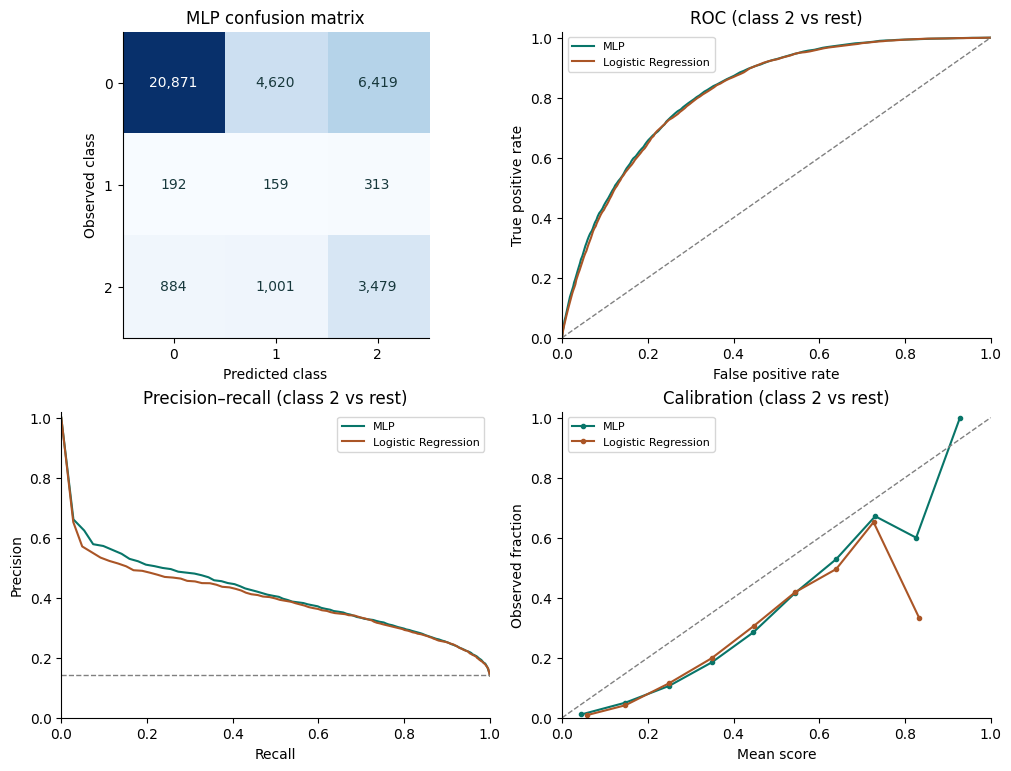

In [6]:
diagnostics = artifact("brfss_diagnostics.json")
fig, axes = plt.subplots(2, 2, figsize=(10, 7.6), layout="constrained")
ax = axes[0, 0]
matrix = np.asarray(brfss["test"]["MLP"]["confusion_matrix"])
ax.imshow(matrix, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{matrix[i, j]:,}", ha="center", va="center",
                color="white" if matrix[i,j] > matrix.max() * .50 else ink)
ax.set(xticks=range(3), yticks=range(3), xlabel="Predicted class", ylabel="Observed class", title="MLP confusion matrix")
for ax, key, title, xlabel, ylabel in (
    (axes[0,1], "roc", "ROC (class 2 vs rest)", "False positive rate", "True positive rate"),
    (axes[1,0], "pr", "Precision–recall (class 2 vs rest)", "Recall", "Precision"),
    (axes[1,1], "calibration", "Calibration (class 2 vs rest)", "Mean score", "Observed fraction"),
):
    for name, color in (("MLP", teal), ("Logistic Regression", amber)):
        curve = diagnostics["curves"][name][key]
        ax.plot(curve["x"], curve["y"], label=name, color=color, marker="o" if key == "calibration" else None, ms=3)
    if key in ("roc", "calibration"):
        ax.plot([0,1], [0,1], "--", color="gray", linewidth=1)
    else:
        ax.axhline(diagnostics["positive_prevalence"], linestyle="--", color="gray", linewidth=1)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel, xlim=(0,1), ylim=(0,1.02))
    ax.legend(fontsize=8)
emit(fig, "04_test_diagnostics")

### Question. What explains the prediction scores?

**Answer.** Explainable AI studies how a model's behavior depends on its inputs. Here permutation importance estimates model reliance on each feature by randomly shuffling one column on a fixed held-out sample and measuring the drop in macro-F1. There are three shuffles per feature over 6,000 test records. Correlated variables can substitute for one another. Negative values can reflect sampling variation or a noisy feature. Importance is a property of this fitted model and dataset, not a causal effect or a patient-specific reason for diagnosis.

The score histogram displays the distribution for class 2. The calibration diagram above addresses whether those scores should be interpreted probabilistically. The bars below report the most influential variables under this particular test.

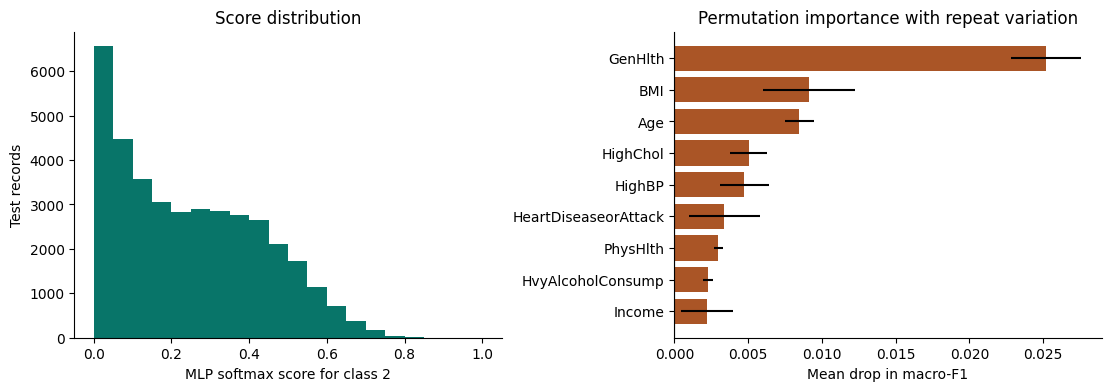

,feature,mean_drop,std_drop
13,GenHlth,0.0252,0.0024
3,BMI,0.0091,0.0031
18,Age,0.0085,0.0010
1,HighChol,0.0050,0.0012
0,HighBP,0.0047,0.0017
6,HeartDiseaseorAttack,0.0034,0.0024
15,PhysHlth,0.0030,0.0003
10,HvyAlcoholConsump,0.0023,0.0004
20,Income,0.0022,0.0018


In [7]:
importance = pd.DataFrame(diagnostics["permutation"]).nlargest(9, "mean_drop").iloc[::-1]
hist = diagnostics["curves"]["MLP"]["score_histogram"]
edges = np.asarray(hist["edges"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].bar(edges[:-1], hist["counts"], width=np.diff(edges), align="edge", color=teal)
axes[0].set(xlabel="MLP softmax score for class 2", ylabel="Test records", title="Score distribution")
axes[1].barh(importance["feature"], importance["mean_drop"], xerr=importance["std_drop"], color=amber)
axes[1].axvline(0, color=ink, linewidth=.8)
axes[1].set(xlabel="Mean drop in macro-F1", title="Permutation importance with repeat variation")
emit(fig, "05_scores_and_importance")
display(importance.iloc[::-1].round(4))

## 4. Data and exploratory analysis

### Question. Which three large datasets were used, and what populations do they represent?

**Answer.** The three datasets are related to diabetes but represent different statistical tasks. They were not pooled or used as interchangeable external validation sets.

| Dataset | Records and features | Target and population | Important limitation |
|---|---|---|---|
| BRFSS 2015, processed | 253,680 rows, 21 features | Three survey-response categories in a processed subset of a US adult telephone survey | Cross-sectional self-report, class imbalance, and limited transfer outside the sampled population |
| Diabetes A2 | 100,000 rows, 10 chosen raw variables, 14 encoded inputs | Supplied binary label in the course dataset | Original collection and clinical representativeness have not been verified independently |
| UCI 130-US Hospitals | 101,766 historical encounters, 11 chosen raw variables, 43 encoded inputs | Recorded readmission within 30 days after qualifying inpatient encounters involving diabetes | Hospital encounters from 1999–2008, with no guarantee of complete subsequent care records |

The model uses BRFSS alone at inference. Assignment 4 contributes BRFSS and archived CNN results for MNIST and CIFAR-10. Assignment 2 contributes the second tabular benchmark. The earlier project contributes the small Pima comparator, with its own split and population limitations. The house-price and AAPL exercises illustrate regression and chronological sequence forecasting. Their RMSE values are not directly comparable with classification metrics.

[CDC survey](https://www.cdc.gov/brfss/annual_data/annual_2015.html) · [Processed BRFSS table](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) · [A2 metadata source](https://www.kaggle.com/datasets/mohankrishnathalla/diabetes-health-indicators-dataset) · [UCI dataset](https://doi.org/10.24432/C5230J)

In [8]:
additional = artifact("additional_experiments.json")
legacy = artifact("assignment_benchmarks.json")
summary = [{"Dataset": "BRFSS 2015", "Records": brfss["rows"], "Encoded inputs": len(brfss["features"]),
            "Test records": brfss["splits"]["test"]["rows"]}]
for run in additional:
    summary.append({"Dataset": run["dataset"], "Records": run["rows"],
                    "Encoded inputs": run["encoded_dimension"], "Test records": run["splits"]["test"]["rows"]})
display(pd.DataFrame(summary))
secondary = pd.DataFrame([{"Dataset": run["dataset"], "Model": name, **score}
                          for run in additional for name, score in run["test"].items()])
display(secondary[["Dataset","Model","macro_f1","roc_auc","average_precision","positive_recall"]].round(4))
display(pd.DataFrame(legacy)[["dataset","model","rows","test","accuracy","metric_name","metric"]].round(4))

,Dataset,Records,Encoded inputs,Test records
0,BRFSS 2015,253680,21,37938
1,Diabetes A2,100000,14,15000
2,UCI 130-US Hospitals,101766,43,15108


,Dataset,Model,macro_f1,roc_auc,average_precision,positive_recall
0,Diabetes A2,MLP,0.6056,0.6632,0.7404,0.5787
1,Diabetes A2,Logistic Regression,0.6020,0.6645,0.7415,0.5569
2,Diabetes A2,Majority,0.3730,0.5000,0.5950,1.0000
3,UCI 130-US Hospitals,MLP,0.5227,0.6306,0.1848,0.4555
4,UCI 130-US Hospitals,Logistic Regression,0.5166,0.6279,0.1838,0.4543
5,UCI 130-US Hospitals,Majority,0.4713,0.5000,0.1087,0.0000


,dataset,model,rows,test,accuracy,metric_name,metric
0,MNIST,CNN · NumPy,70000,10000,0.9790,Macro-F1,0.9788
1,MNIST,CNN · PyTorch,70000,10000,0.9753,Macro-F1,0.9752
2,MNIST,CNN · Keras,70000,10000,0.9780,Macro-F1,0.9779
3,CIFAR-10,CNN · NumPy,60000,10000,0.5729,Macro-F1,0.5727
4,CIFAR-10,CNN · PyTorch,60000,10000,0.5737,Macro-F1,0.5647
5,CIFAR-10,CNN · Keras,60000,10000,0.5681,Macro-F1,0.5638
6,Pima,MLP,768,116,0.7328,ROC-AUC,0.8537
7,Pima,Logistic,768,116,0.7672,ROC-AUC,0.8608


### Question. What do the class distribution, missingness, and outliers reveal?

**Answer.** The processed BRFSS CSV is the source for this exploratory analysis. A missing value is an absent observation rather than an out-of-range numeric value. The left panels show whether the label is balanced and whether any cells are blank in this processed copy. The right panels examine BMI and group differences. A boxplot's whiskers use a 1.5-interquartile-range convention. A tail point can be a valid observation, so we check the data dictionary and do not discard observations just because they appear in a tail. The violin plot describes distributions by label using a deterministic sample from each group.

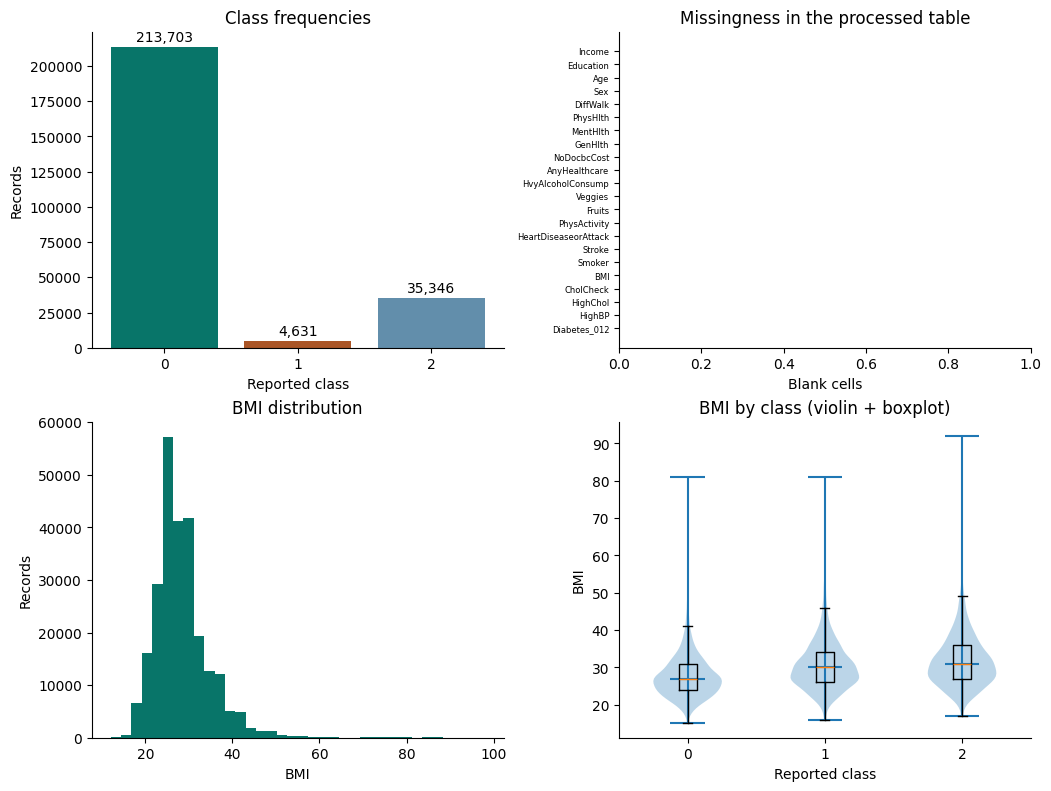

Total blank cells: 0
Observed BMI range: 12 to 98


,BMI,GenHlth,Age
Class,,,
0.0,27.0,2.0,8.0
1.0,30.0,3.0,9.0
2.0,31.0,3.0,10.0


In [9]:
assert DATA.is_file(), f"BRFSS dataset is missing: {DATA}"
df = pd.read_csv(DATA)
label = df["Diabetes_012"].astype(int)
counts = label.value_counts().sort_index()
missing = df.isna().sum()
fig, axes = plt.subplots(2, 2, figsize=(10.4, 7.8), layout="constrained")
axes[0,0].bar(counts.index, counts.values, color=[teal, amber, "#628eab"])
axes[0,0].set(xticks=[0,1,2], xlabel="Reported class", ylabel="Records", title="Class frequencies")
axes[0,0].bar_label(axes[0,0].containers[0], labels=[f"{count:,}" for count in counts], padding=2)
axes[0,1].barh(range(len(missing)), missing.values, color=teal)
axes[0,1].set(yticks=range(len(missing)), yticklabels=missing.index, xlabel="Blank cells", title="Missingness in the processed table")
axes[0,1].tick_params(axis="y", labelsize=6)
axes[0,1].set_xlim(0, max(1, missing.max()))
axes[1,0].hist(df["BMI"], bins=36, color=teal)
axes[1,0].set(xlabel="BMI", ylabel="Records", title="BMI distribution")
groups = [df.loc[label.eq(code), "BMI"] for code in (0,1,2)]
sample = [group.sample(min(len(group), 2000), random_state=42) for group in groups]
axes[1,1].violinplot(sample, positions=[0,1,2], showmedians=True)
axes[1,1].boxplot(sample, positions=[0,1,2], widths=.13, showfliers=False)
axes[1,1].set(xticks=[0,1,2], xlabel="Reported class", ylabel="BMI", title="BMI by class (violin + boxplot)")
emit(fig, "06_brfss_eda")
print("Total blank cells:", int(missing.sum()))
print("Observed BMI range:", int(df.BMI.min()), "to", int(df.BMI.max()))
display(df.groupby("Diabetes_012")[["BMI","GenHlth","Age"]].median().rename_axis("Class").round(2))

### Question. How did preprocessing avoid leakage?

**Answer.** Class 1 is far less common than class 0, and the processed table contains no blank cells. BMI has a right tail and group distributions overlap. These descriptive patterns do not establish causation or identify individuals. The heatmap summarizes associations among selected coded features. Pearson correlation is a rough descriptive measure for binary and ordinal codes, so interpretation should respect each variable's scale.

We hash each 21-feature profile and split by group, keeping identical feature vectors together. Training, validation, and test contain 177,745, 37,997, and 37,938 rows. Standardization uses $z=(x-\mu_{\mathrm{train}})/\sigma_{\mathrm{train}}$. For example, a BMI of 30 with training mean 28 and standard deviation 5 becomes 0.4. Fitting the scaler on validation or test would leak information from held-out data. The code checks the exported training summary and saved scaler. A2 and UCI use training-only imputation, numeric scaling, and one-hot encoding. UCI groups repeated encounters by patient ID.

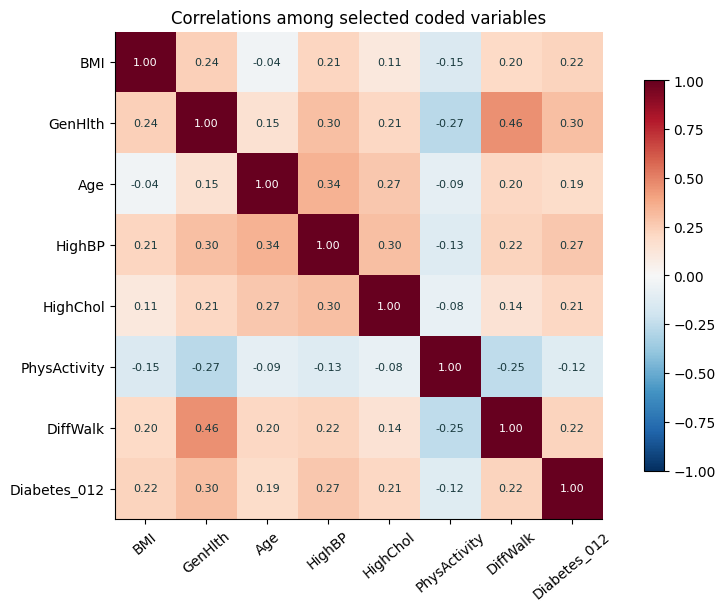

,rows,feature_profiles,class_counts
train,177745,159534,"{'0': 149874, '1': 3276, '2': 24595}"
validation,37997,34187,"{'0': 31919, '1': 691, '2': 5387}"
test,37938,34187,"{'0': 31910, '1': 664, '2': 5364}"


,feature,train_mean,train_scale
0,HighBP,0.428,0.495
1,HighChol,0.421,0.494
2,CholCheck,0.963,0.190
3,BMI,28.368,6.613
4,Smoker,0.443,0.497
5,Stroke,0.041,0.197
6,HeartDiseaseorAttack,0.094,0.292
7,PhysActivity,0.757,0.429


In [10]:
fields = ["BMI","GenHlth","Age","HighBP","HighChol","PhysActivity","DiffWalk","Diabetes_012"]
corr = df[fields].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.0), layout="constrained")
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(len(fields)), yticks=range(len(fields)), xticklabels=fields,
       yticklabels=fields, title="Correlations among selected coded variables")
ax.tick_params(axis="x", labelrotation=40)
for i in range(len(fields)):
    for j in range(len(fields)):
        value = corr.iloc[i,j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > .60 else ink)
fig.colorbar(image, ax=ax, shrink=.8)
emit(fig, "07_correlation")
display(pd.DataFrame(brfss["splits"]).T)
saved = torch.load(ARTIFACTS / "mlp.pt", map_location="cpu", weights_only=True)
assert saved["features"] == list(FEATURES)
assert all(scale > 0 for scale in saved["scale"])
display(pd.DataFrame({"feature": saved["features"], "train_mean": saved["mean"],
                      "train_scale": saved["scale"]}).head(8).round(3))

## 5. Knowledge base, Neo4j, and RAG

### Question. Which websites and PDFs are used, and where is the Cypher knowledge base?

**Answer.** The project stores one editable, bilingual source bundle per URL. Each bundle contains publisher, URL, type, scope, review date, and curated passages. It may also contain graph relationships that those passages support. Unverified publication dates are left empty. There are **20 diabetes education web URLs** and two data-provenance resources. The web sources include WHO, NIDDK/NIH, CDC, Vinmec, and FPT Long Chau. Vinmec and Long Chau are supplementary sources. The [CDC BRFSS PDF, page 21](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=21) explains the survey question.

[build_kb.py](../knowledge_base/build_kb.py) validates IDs, URLs, concept references and edge evidence, then combines all source bundles into [kb_diabetes.json](../knowledge_base/kb_diabetes.json) and compiles [kb_diabet.cypher](../knowledge_base/cypher/kb_diabet.cypher). The Cypher file is located in the knowledge base's Cypher directory. The next cell prints the resolved path on the machine running the notebook. Run the builder after editing a bundle and use [seed.py](../knowledge_base/seed.py) to import into the dedicated local Neo4j database. Neo4j Browser is available at [127.0.0.1:7476](http://127.0.0.1:7476/browser/).

The graph uses three node labels: Concept, Passage, and Source. An ABOUT edge links a passage to a topic. FROM_SOURCE records its provenance. Semantic edges include ASSESSED_BY and CLASSIFIED_WITH. Each semantic edge refers to its supporting passage. The code below verifies that the merged files match their source bundles, then displays the source manifest.

In [11]:
from knowledge_base.build_kb import SEED, build

kb_data = build(check=True)
print("Cypher seed:", SEED)
source_table = pd.DataFrame(kb_data["sources"])
display(source_table[["id","publisher","title","kind","tier","url"]])
bundle_counts = {
    "Source files": len(list((root / "knowledge_base/sources").glob("*.json"))),
    "Distinct education URLs": int(((source_table.kind == "Web") &
                                    source_table.tier.isin(["Public health","Supplementary"])).sum()),
    "Concepts": len(kb_data["concepts"]), "Passages": len(kb_data["passages"]),
    "Semantic relationships": len(kb_data["relationships"]),
}
display(pd.DataFrame([bundle_counts]))

Cypher seed: C:\Users\ADMIN\Downloads\Intelligent System\Diabetes_Hybrid_Lab\diabetes_hybrid\knowledge_base\cypher\kb_diabet.cypher


,id,publisher,title,kind,tier,url
0,a1c,NIDDK / NIH,The A1C Test & Diabetes,Web,Public health,https://www.niddk.nih.gov/health-information/d...
1,cdcdka,CDC,Diabetic Ketoacidosis,Web,Public health,https://www.cdc.gov/diabetes/about/diabetic-ke...
2,cdclow,CDC,Low Blood Sugar (Hypoglycemia),Web,Public health,https://www.cdc.gov/diabetes/about/low-blood-s...
3,codebook,CDC,BRFSS 2015 Codebook Report (page 21),PDF,Public health,https://www.cdc.gov/brfss/annual_data/2015/pdf...
4,curated,Alex Teboul,Diabetes Health Indicators Dataset,Dataset,Dataset metadata,https://www.kaggle.com/datasets/alexteboul/dia...
5,footguide,NIDDK / NIH,Diabetes & Foot Problems,Web,Public health,https://www.niddk.nih.gov/health-information/d...
6,gestoverview,NIDDK / NIH,Gestational Diabetes,Web,Public health,https://www.niddk.nih.gov/health-information/d...
7,gesttests,NIDDK / NIH,Tests & Diagnosis for Gestational Diabetes,Web,Public health,https://www.niddk.nih.gov/health-information/d...
8,longfast,FPT Long Chau,Does diabetes testing require fasting?,Web,Supplementary,https://nhathuoclongchau.com.vn/bai-viet/truoc...
9,longfollow,FPT Long Chau,What else to monitor to prevent diabetes compl...,Web,Supplementary,https://nhathuoclongchau.com.vn/bai-viet/nguoi...


,Source files,Distinct education URLs,Concepts,Passages,Semantic relationships
0,22,20,21,27,19


### Question. How does the RAG-KB work, and where is its code and link?

**Answer.** Retrieval-augmented generation (RAG) grounds a response in evidence retrieved at question time. An LLM is a neural language model trained to predict text. It can produce plausible but unsupported statements because fluent text is not necessarily verified. A generative system would pass passages to an LLM and then validate its claims and citations. Our local implementation instead extracts a reviewed passage as the answer. It uses no LLM, dense embedding model, API key, or live web search.

The ingestion pipeline is **selected sources → editorial cleaning and passage division → bilingual source bundles → Neo4j import**. The query pipeline is **scope check → alias resolution → parameterized Cypher → sparse vector ranking → cited answer**. TF-IDF assigns larger weight to character fragments that occur in a candidate and are less common in other candidates. Similarity is cosine $\cos(\mathbf{q},\mathbf{d})=\mathbf{q}^{\top}\mathbf{d}/(\|\mathbf{q}\|\,\|\mathbf{d}\|)$, where $\mathbf{q}$ and $\mathbf{d}$ represent the question and passage. Graph matches and source tiers contribute to reranking. BM25 uses term-frequency saturation and document-length normalization. Dense embeddings can help recover paraphrases, but require a separate representation and validation. The graph preserves topic links and provenance that either text-ranking method would otherwise lack.

The implementation is [rag.py](../core/rag.py) and [retrieve.cypher](../knowledge_base/cypher/retrieve.cypher). The live interface is the [Vietnamese chat](http://127.0.0.1:8011/#demo). The following demo uses the same retrieval logic with English passages and a two-turn contextual question.

[Lewis et al., original RAG paper](https://papers.nips.cc/paper/2020/hash/6b493230205f780e1bc26945df7481e5-Abstract.html) · [scikit-learn TF-IDF documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)

In [12]:
from neo4j.exceptions import DriverError, Neo4jError
from core.rag import GraphRAG, connect

driver = None
kb = None
try:
    driver = connect()
    candidate = GraphRAG(driver)
    live = candidate.status()
    if live["ready"]:
        kb = candidate
except (ValueError, OSError, DriverError, Neo4jError):
    live = checks["graph"]

display(pd.DataFrame(live["nodes"]).sort_values("label"))
if kb:
    relation = kb.query(
        "MATCH (:Concept)<-[r:CLASSIFIED_WITH]-(:Concept {id:'type1'})"
        "<-[:ABOUT]-(p:Passage)-[:FROM_SOURCE]->(s:Source) "
        "WHERE p.id = r.passage_id RETURN type(r) AS relationship, p.title AS passage, s.url AS source"
    )
    display(pd.DataFrame(relation))
    topic = None
    for prompt in ("What is gestational diabetes?", "What about blood tests?",
                   "Does HbA1c need to fast?", "What is diabetic ketoacidosis?"):
        answer = kb.answer(prompt, context=topic, language="en")
        topic = answer.get("context")
        print("Question:", prompt)
        if answer["status"] == "ok":
            print("Answer:", answer["evidence"][0]["text"])
            for item in answer["evidence"]:
                print("Source:", item["source"]["publisher"], "|", item["source"]["url"])
        else:
            print("Answer:", answer["message"])
        print()
else:
    print("Live Neo4j is unavailable. Stored graph statistics are shown above.")
if driver:
    driver.close()

,label,total
0,Concept,21
2,Passage,27
1,Source,22


,relationship,passage,source
0,CLASSIFIED_WITH,Blood tests and diabetes classification,https://www.niddk.nih.gov/health-information/d...


Question: What is gestational diabetes?
Answer: Gestational diabetes is a form of diabetes that develops during pregnancy. It can affect the health of both the pregnant person and baby. Prenatal screening can identify it even when symptoms are absent.
Source: NIDDK / NIH | https://www.niddk.nih.gov/health-information/diabetes/overview/what-is-diabetes/gestational
Source: FPT Long Chau | https://nhathuoclongchau.com.vn/benh/tieu-duong-thai-ky.html
Source: NIDDK / NIH | https://www.niddk.nih.gov/health-information/diabetes/overview/what-is-diabetes/gestational/tests-diagnosis

Question: What about blood tests?
Answer: NIDDK describes routine gestational diabetes testing around weeks 24â€“28. Testing may occur earlier in selected patients. The test method and interpretation are determined by the prenatal care team.
Source: NIDDK / NIH | https://www.niddk.nih.gov/health-information/diabetes/overview/what-is-diabetes/gestational/tests-diagnosis
Source: FPT Long Chau | https://nhathuoclongch

### Question. How do we measure retrieval quality and safe handling?

**Answer.** We define one reference passage per relevant test case. Recall@3 is the fraction of these cases for which that passage appears in the first three positions. Precision@3 in this notebook uses only the annotated passage as credit and divides by three, treating empty slots as zero. This is a conservative reference-only measure, not a full relevance judgment. The annotated tests cover the curated corpus, so they do not estimate open-world accuracy. Other cases exercise refusal, medical referral, and emergency guidance. Timing is from a local test client and is not a hosting benchmark.

We also count whether a successful answer contains source links. Provenance improves auditability, but a link alone cannot establish clinical correctness. Actual emergency behavior cannot be validated by a handful of language examples.

Integration checks cover the optional question, original checkpoint parity, structured reporting, close-score escalation, and deliberately conflicting synthetic evidence. Synthetic conflicting statements are test fixtures and are absent from the live Neo4j knowledge graph.


,Result
Integration check,
optional_question,passed
structured_report,passed
assignment4_reuse,passed
separate_grouped_checkpoint,passed
synthetic_close_scores,passed
synthetic_source_conflict,passed
different_scope_and_unapproved_sources,passed
live_consistent_claims,passed
urgent_route,passed


,Question cases,Cases with reference,Hit at rank 1,Hit within top 3,Recall at 3,Reference-only precision at 3,Median time (ms),95th percentile time (ms)
0,39,30,25,30,1.0,0.333,40.62,870.02


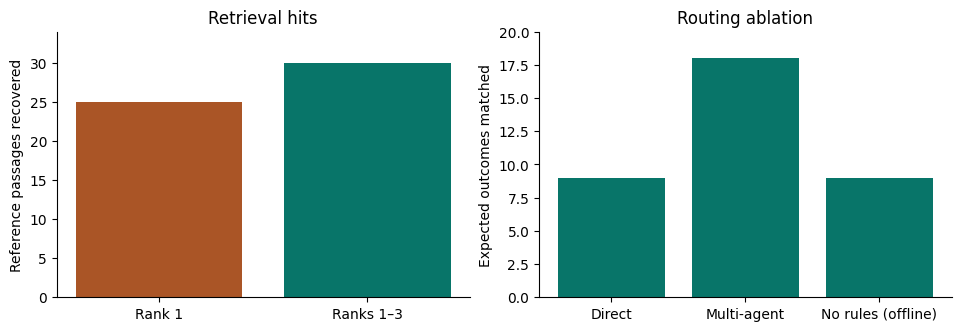

In [13]:
checks = artifact("demo_verification.json")
display(pd.Series(checks["report_checks"], name="Result").rename_axis("Integration check").to_frame())
retrieval_summary = {
    "Question cases": checks["qa_cases"], "Cases with reference": checks["retrieval_cases"],
    "Hit at rank 1": checks["hits_at_1"], "Hit within top 3": checks["hits_at_3"],
    "Recall at 3": checks["hits_at_3"] / checks["retrieval_cases"],
    "Reference-only precision at 3": checks["reference_precision_at_3"],
    "Median time (ms)": checks["median_ms"], "95th percentile time (ms)": checks["p95_ms"],
}
display(pd.DataFrame([retrieval_summary]).round(3))
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), layout="constrained")
axes[0].bar(["Rank 1", "Ranks 1–3"], [checks["hits_at_1"], checks["hits_at_3"]], color=[amber, teal])
axes[0].set(ylabel="Reference passages recovered", ylim=(0, checks["retrieval_cases"] + 4), title="Retrieval hits")
probe = pd.DataFrame(checks["architecture_probe"])
axes[1].bar(["Direct", "Multi-agent", "No rules (offline)"], probe["expected_status_matches"], color=teal)
axes[1].set(ylabel="Expected outcomes matched", ylim=(0, probe.requests.max() + 2), title="Routing ablation")
emit(fig, "08_retrieval_and_routing")

## 6. Installation, demonstration, and deployment artifacts

### Question. How do I run and demonstrate the system?

**Answer.** Use Python 3.13 and install the project requirements. Use a local authenticated Neo4j instance, then run the builder and seed. Start the app from the project folder with **python app.py** and open the [Vietnamese web demo](http://127.0.0.1:8011/). The [README](../README.md) includes connection and troubleshooting steps. The notebook's report remains in English, while user-facing chat and controls are in Vietnamese.

1. Start with a general pregnancy-related diabetes question and ask a short follow-up about testing. Show the two questions, answers, and source links.
2. Select synthetic profile B or edit the 21 survey fields, then run both branches with a type 1 testing question. Explain why a BRFSS class score cannot establish a clinical diagnosis.
3. Try a fictional medication or urgent-symptom example. Show the scope gate and next-step message.
4. Open the dashboard, compare the MLP against its baselines, then use [Neo4j Browser](http://127.0.0.1:7476/browser/) and the [example queries](../knowledge_base/cypher/examples.cypher) to trace a passage back to its source.

The code exercises prediction and routing locally. It prints only English agent identifiers and status codes. The Vietnamese screenshots are linked below as evidence of the actual browser demo.

[Live demo walkthrough](../docs/DEMO_GUIDE_VI.md)

In [14]:
from core.model import FEATURES

smoke = client.get("/")
assert smoke.status_code == 200
print("Dashboard:", smoke.status_code)
synthetic = {field: spec[2] for field, spec in FEATURES.items()}
prediction_response = client.post("/api/run", json={"mode":"predict", "synthetic":True, "features":synthetic})
assert prediction_response.status_code == 200
pred = prediction_response.get_json()["prediction"]
print("Model version:", pred["model_version"], "| Output dimension:", len(pred["scores"]))
print("Sum of the softmax scores:", round(sum(pred["scores"]), 6))
case = client.post("/api/run", json={"mode":"qa", "question":"My A1c is 8.1. Do I have diabetes?"}).get_json()
print("Personal-result route:", case["knowledge"]["status"], "| Provides next step:", bool(case["knowledge"].get("next_step")))
assert case["knowledge"]["status"] == "blocked"

Dashboard: 200
Model version: assignment4-original | Output dimension: 3
Sum of the softmax scores: 1.0
Personal-result route: blocked | Provides next step: True


### Question. What was saved, and can the exported model be loaded again?

**Answer.** The application loads both PyTorch checkpoints with their feature order, training means, scales, and version. The original checkpoint was packaged directly from Assignment 4. The round-trip below concerns the separate grouped checkpoint. The training configuration, decision rule, seed, and epoch history are in [experiment.json](../artifacts/experiment.json). [brfss_diagnostics.json](../artifacts/brfss_diagnostics.json) contains test curve points and permutation results. [kb_diabetes.json](../knowledge_base/kb_diabetes.json) and the [per-source bundles](../knowledge_base/sources/) preserve the knowledge configuration. The live agents use these artifacts without starting a training run.

The code below writes a temporary copy of the checkpoint and compares fresh predictions before and after serialization. It uses an artificial input profile. A successful round-trip verifies the deployment path but does not test model generalization.

### Conclusion

This project demonstrates a verifiable path from data and model evaluation to a bilingual source-grounded system. It also shows why evidence and model scores should remain separate. The model's poor minority-class recall and imperfect calibration make the survey score unsuitable as clinical advice. The assistant can support learning and preparation for a clinical conversation. Extending it to clinical diagnosis would require a defined indication, suitable patient data, external and prospective validation, and professional oversight.

**Project materials.** [English presentation Q&A](../docs/PRESENTATION_QA.md) · [English guide](../README.md) · [Vietnamese follow-up demo](../demo/05_chat_followup_vi.png) · [Vietnamese emergency routing](../demo/06_urgent_routing_vi.png) · [Local Neo4j screenshot](../demo/04_neo4j_browser.png).

In [15]:
from tempfile import TemporaryDirectory

profile = [spec[2] for spec in FEATURES.values()]
profile[list(FEATURES).index("BMI")] = 33
before = Predictor().predict(profile)
with TemporaryDirectory() as folder:
    copy_path = Path(folder) / "checkpoint.pt"
    torch.save(saved, copy_path)
    after = Predictor(copy_path).predict(profile)
np.testing.assert_allclose(before["scores"], after["scores"], atol=1e-7, rtol=0)
assert before["class_id"] == after["class_id"]
labels_en = ["No reported diabetes", "Reported prediabetes", "Reported diabetes"]
display(pd.DataFrame({"Class":labels_en,"Before export":before["scores"],"After reload":after["scores"]}).round(5))
print("Round-trip matched within absolute tolerance 1e-7.")

,Class,Before export,After reload
0,No reported diabetes,0.56308,0.56308
1,Reported prediabetes,0.29281,0.29281
2,Reported diabetes,0.14411,0.14411


Round-trip matched within absolute tolerance 1e-7.


#Demo
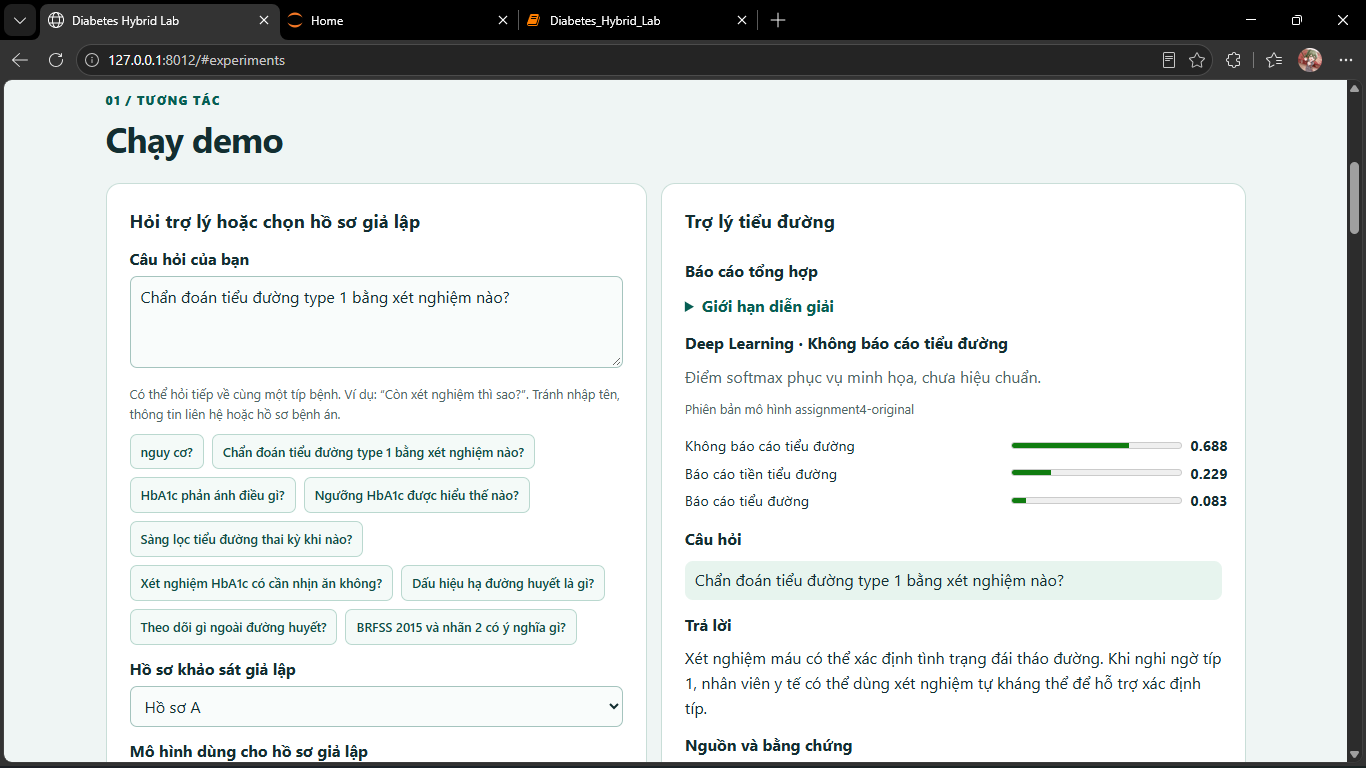
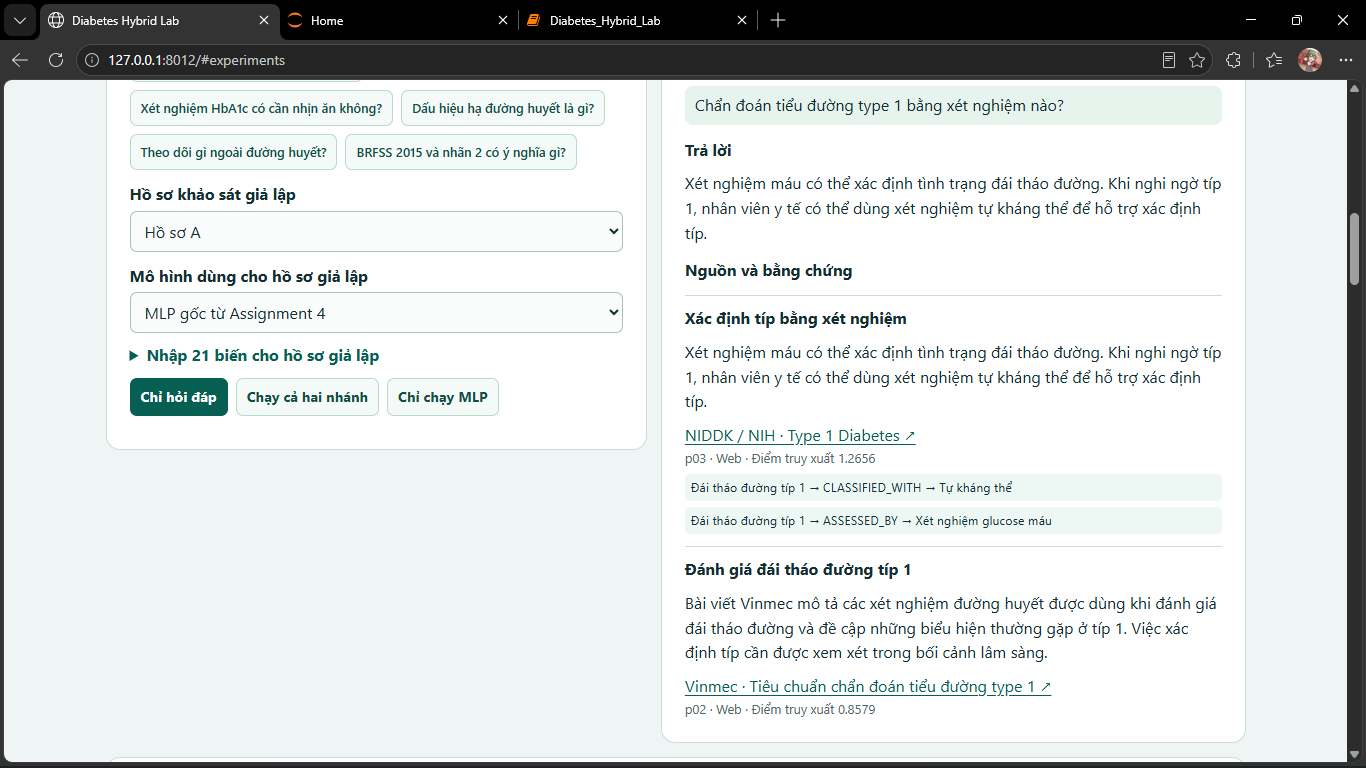
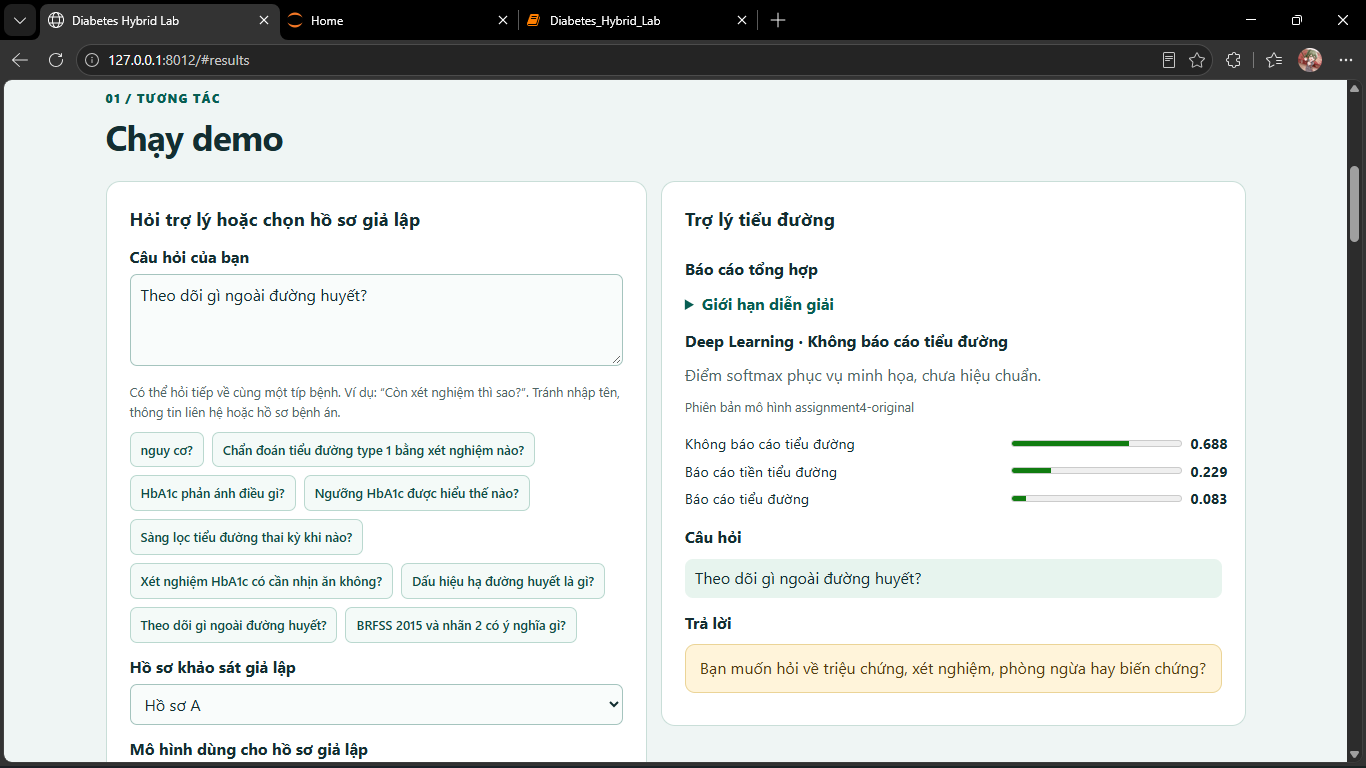
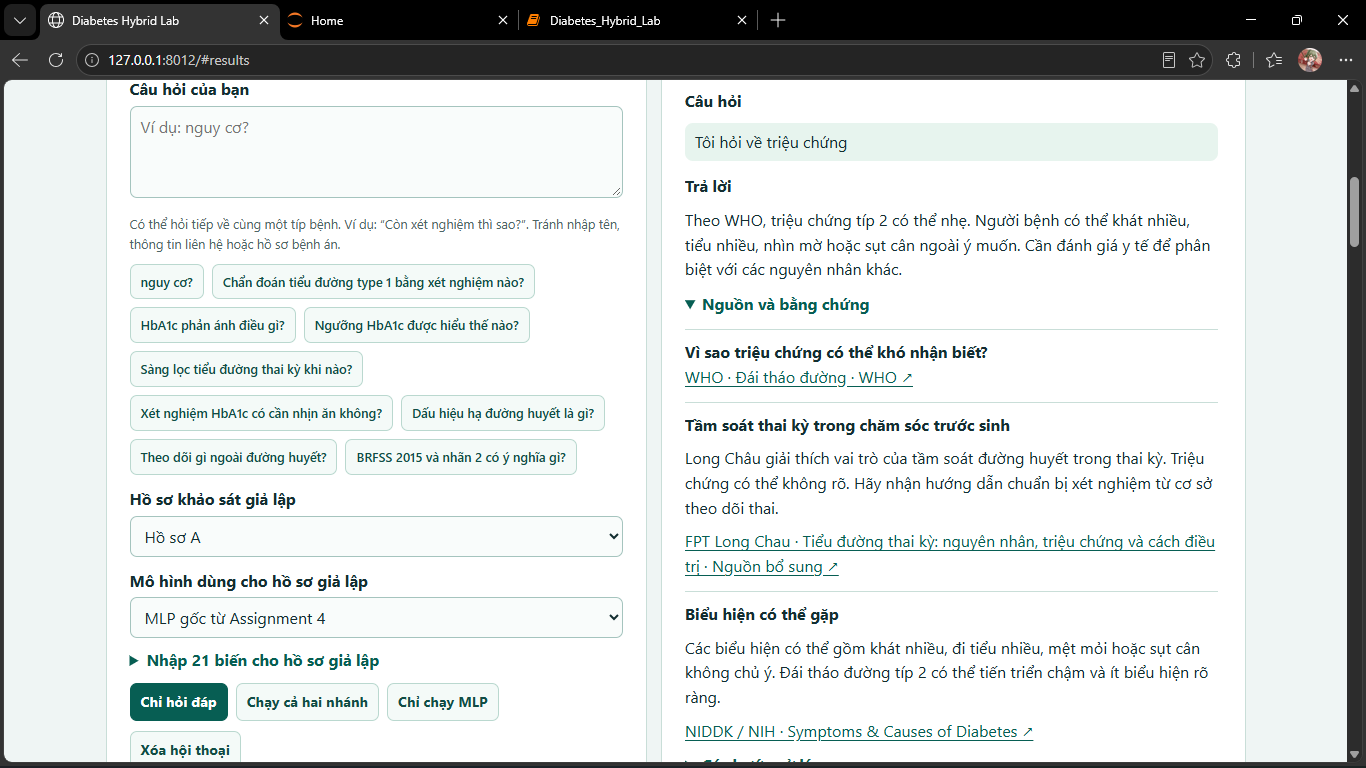
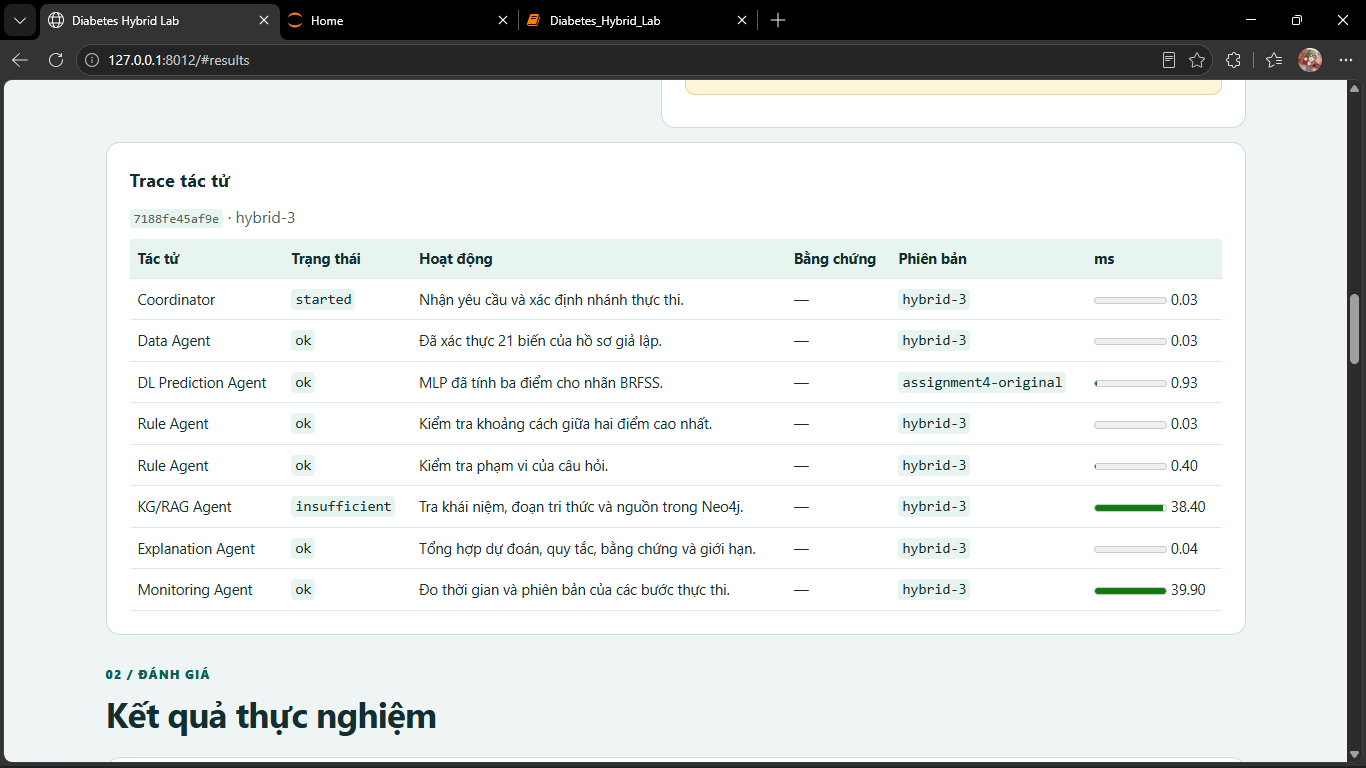
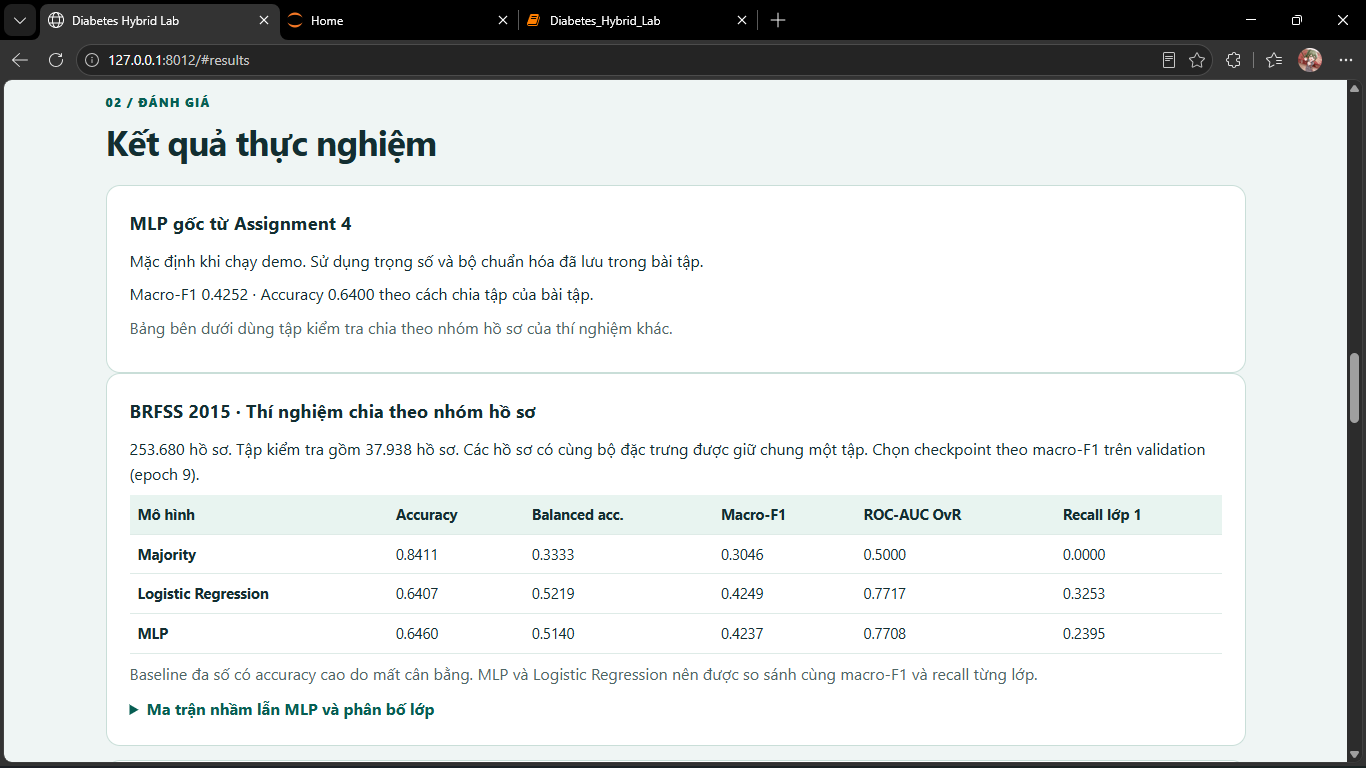
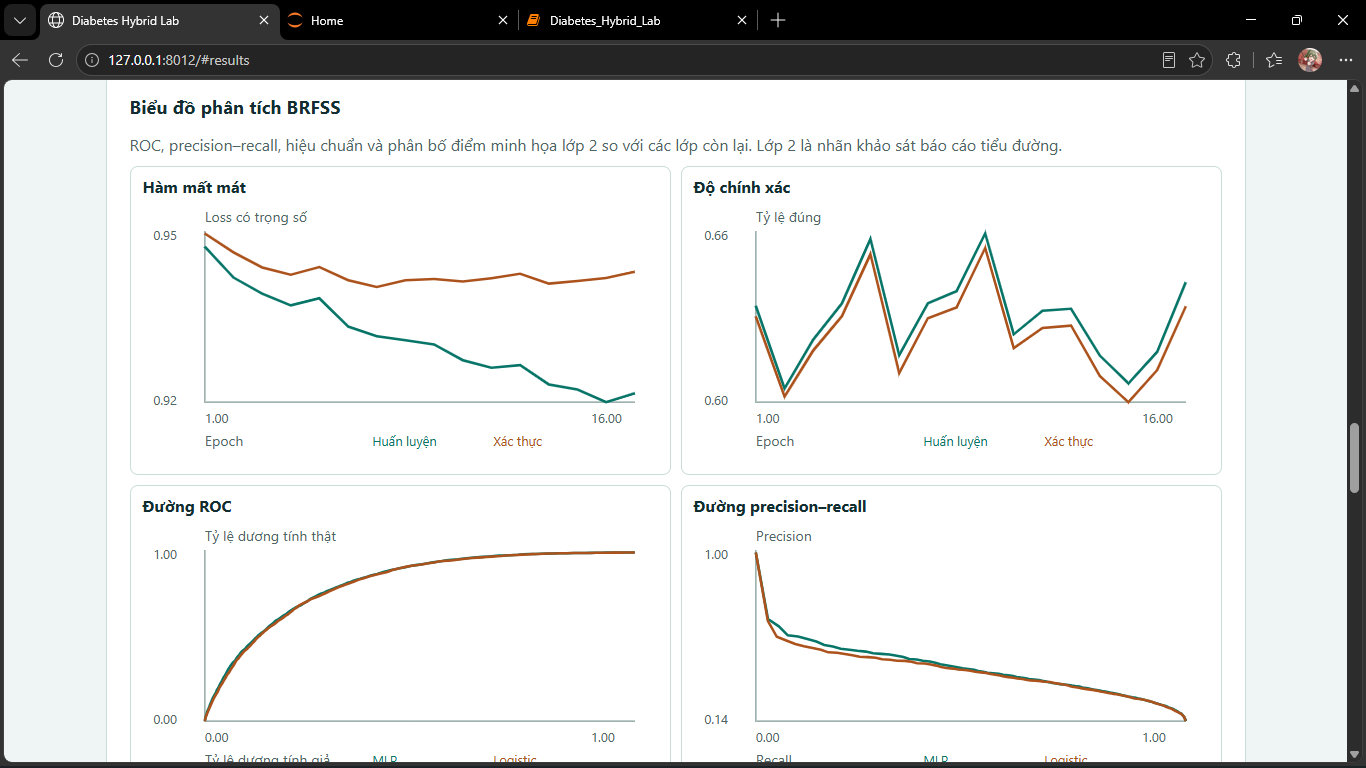
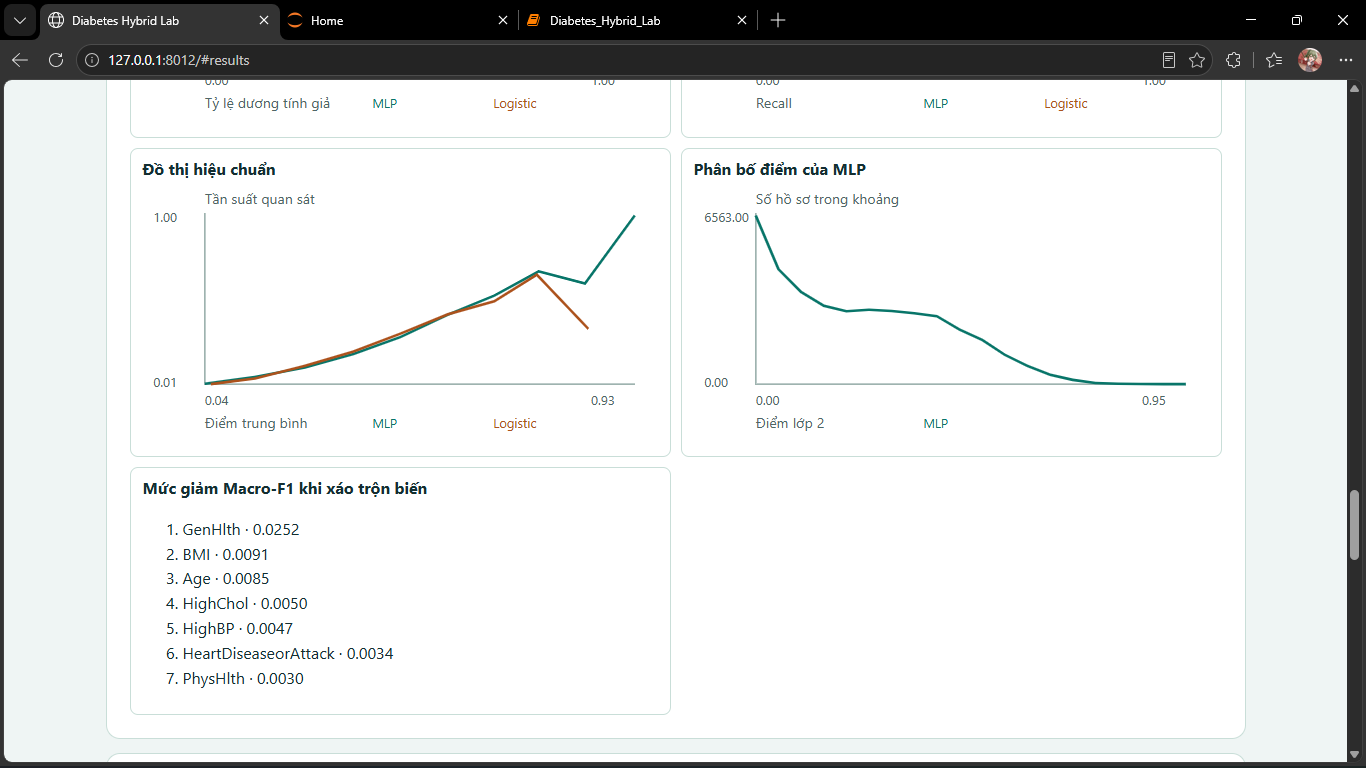
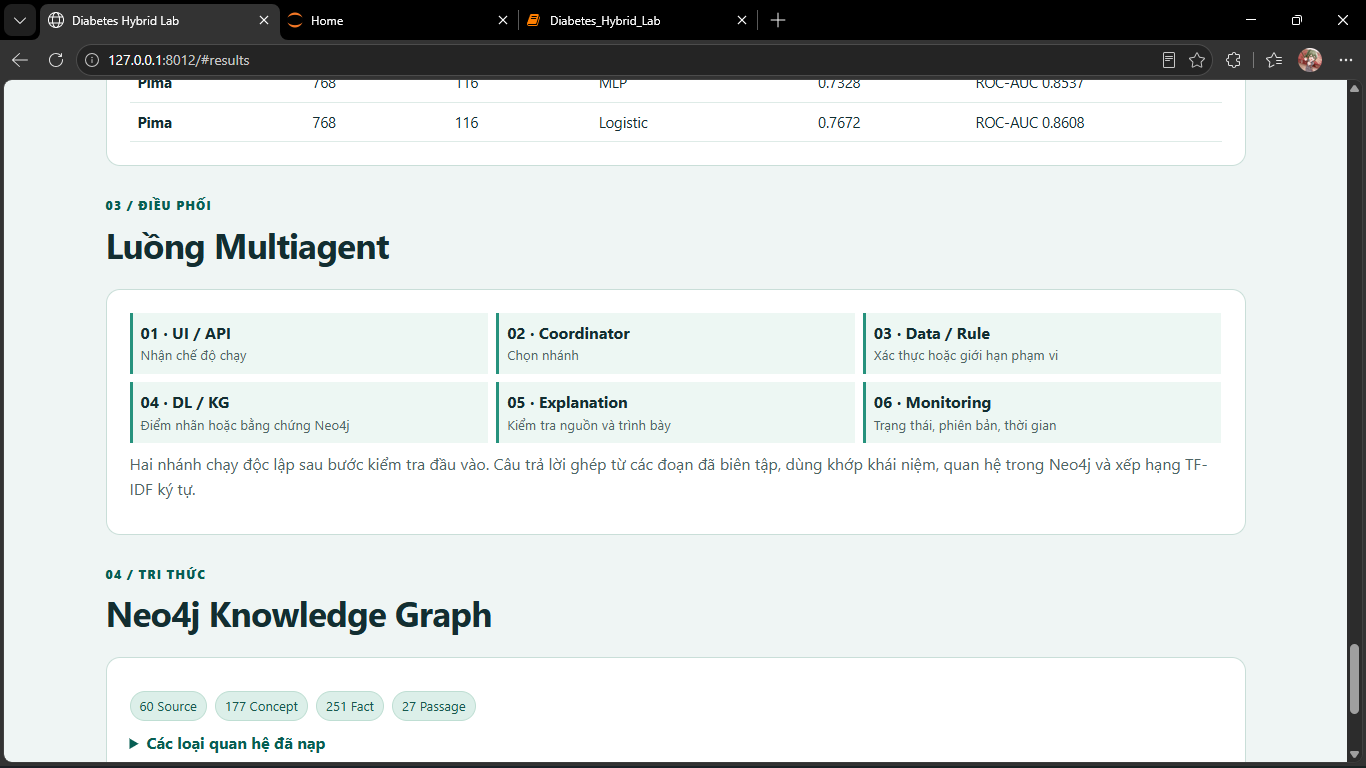
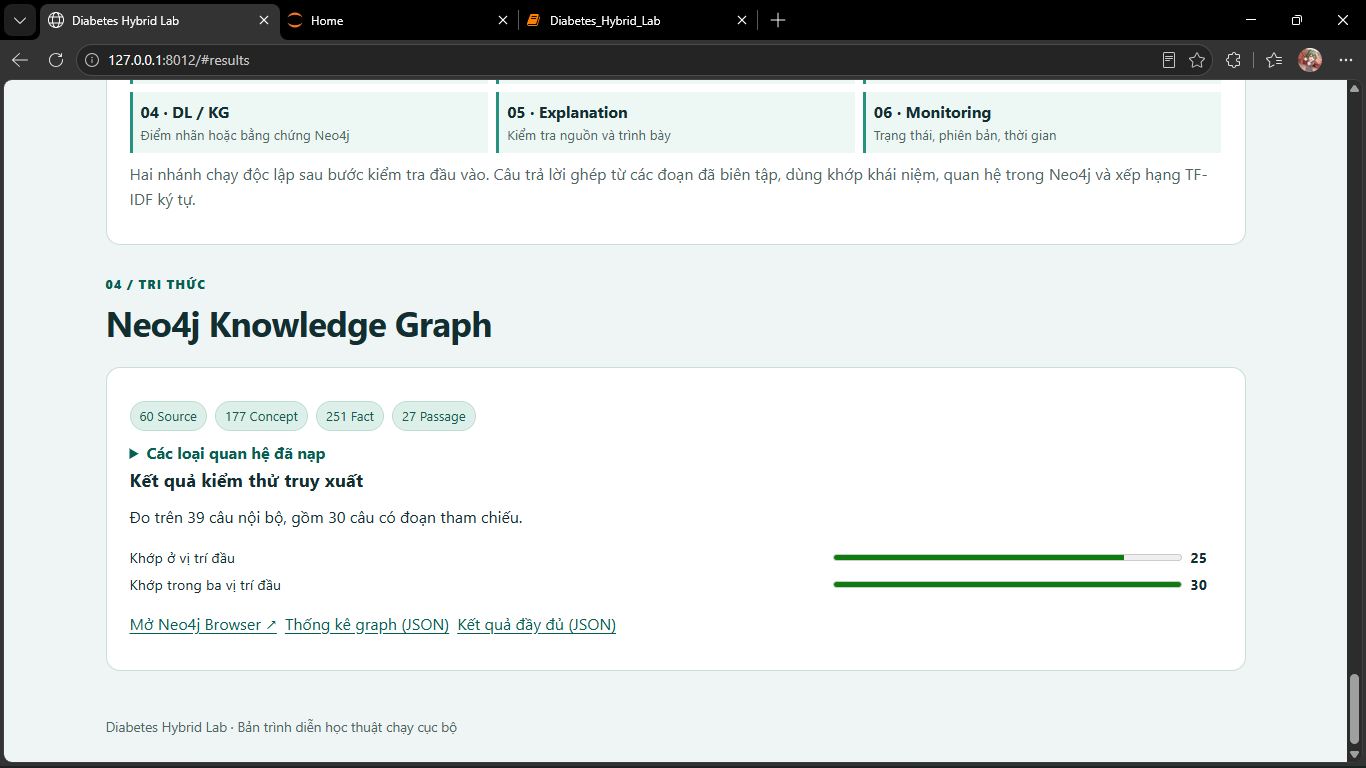